# Use-case visualizations

Model: `cbm_cd275000_res768` (step 50k, KL w=0.5, taxv2), predicted at 768 px, on the 33 viable test sources
(see `Coral_Cover_Live_CD275k_Res768_Regions.ipynb`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["cmr10", "Computer Modern Roman"],
    "mathtext.fontset": "cm",
    "axes.formatter.use_mathtext": True,  # cmr10 has no minus glyph; mathtext draws tick-label minus signs
})

CC = Path("../eval_out/coral_cover")
REGIONS = {
    "Tropical Atlantic": [1304, 1642, 4091, 5181, 6494, 6702, 7049],
    "Western Indo-Pacific": [2615, 2616, 4342, 4816],  # 4721 excluded: bleaching labels have no order (GT too low)
    "Central Indo-Pacific": [290, 1776, 3350, 6673, 2052, 2955, 3606, 6391, 4957, 7116],
    "Eastern Indo-Pacific": [1990, 2682, 3357, 4280, 6551, 6405, 3697, 5227],
    "Temperate Australasia": [2311, 2655, 3656],
}
COLORS = {"All test data": "#003d3c", "Tropical Atlantic": "#849946", "Western Indo-Pacific": "#99465b",
          "Central Indo-Pacific": "#469984", "Eastern Indo-Pacific": "#5b4699", "Temperate Australasia": "#334267"}

## Live coral cover: survey error vs number of images

Mean |survey estimate − ground-truth cover| over `R` random n-image surveys, model from all pixels.

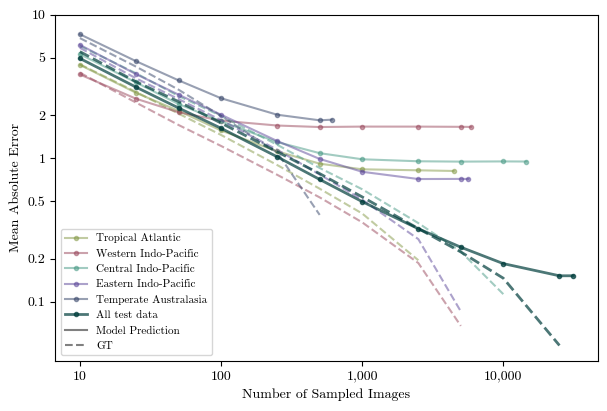

In [2]:
R = 2_000
N_GRID = [10, 25, 50, 100, 250, 500, 1000, 2500, 5000, 10_000, 25_000]
rng = np.random.default_rng(0)

cover = pd.read_parquet(CC / "coralnet_test_pred_cd275k_res768_step50000_viable.parquet")
cover["truth"] = cover.n_live_gt / cover.n_points
groups = {**REGIONS, "All test data": sum(REGIONS.values(), [])}


def mean_abs_error(x, ns):
    """Mean over R random n-image surveys (without replacement) of |survey mean − mean of x[0] over all images|,
    for every row of x (x[0] = ground truth); every row is scored on the same surveys."""
    err = np.zeros((len(x), len(ns)))
    for _ in range(R):
        cs = np.cumsum(x[:, rng.permutation(x.shape[1])], axis=1)
        err += np.abs(cs[:, np.array(ns) - 1] / ns - x[0].mean())
    return err / R


fig, ax = plt.subplots(figsize=(7, 4.5))
for g, sources in groups.items():
    d = cover[cover.source_id.isin(sources)]
    ns = [n for n in N_GRID if n < len(d)] + [len(d)]
    gt, model = mean_abs_error(d[["truth", "dense_live"]].to_numpy().T, ns)
    lw, alpha = (2, 0.7) if g == "All test data" else (1.5, 0.5)
    ax.plot(ns, 100 * model, marker="o", ms=3, color=COLORS[g], lw=lw, alpha=alpha, label=g)
    ax.plot(ns[:-1], 100 * gt[:-1], ls="--", color=COLORS[g], lw=lw, alpha=alpha)  # 0 at all images: off the log axis
ax.set(xscale="log", yscale="log", xlabel="Number of Sampled Images", ylabel="Mean Absolute Error")
ax.set_xticks([10, 100, 1000, 10_000], ["10", "100", "1,000", "10,000"])
ax.set_yticks([0.1, 0.2, 0.5, 1, 2, 5, 10], ["0.1", "0.2", "0.5", "1", "2", "5", "10"])
ax.minorticks_off()
ax.legend(handles=ax.get_legend_handles_labels()[0] + [
    plt.Line2D([], [], color="gray", label="Model Prediction"),
    plt.Line2D([], [], color="gray", ls="--", label="GT")], fontsize=8)
plt.show()

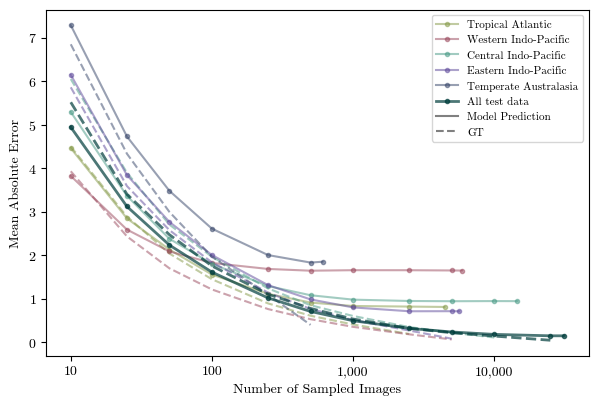

In [3]:
R = 2_000
N_GRID = [10, 25, 50, 100, 250, 500, 1000, 2500, 5000, 10_000, 25_000]
rng = np.random.default_rng(0)

cover = pd.read_parquet(CC / "coralnet_test_pred_cd275k_res768_step50000_viable.parquet")
cover["truth"] = cover.n_live_gt / cover.n_points
groups = {**REGIONS, "All test data": sum(REGIONS.values(), [])}


def mean_abs_error(x, ns):
    """Mean over R random n-image surveys (without replacement) of |survey mean − mean of x[0] over all images|,
    for every row of x (x[0] = ground truth); every row is scored on the same surveys."""
    err = np.zeros((len(x), len(ns)))
    for _ in range(R):
        cs = np.cumsum(x[:, rng.permutation(x.shape[1])], axis=1)
        err += np.abs(cs[:, np.array(ns) - 1] / ns - x[0].mean())
    return err / R


fig, ax = plt.subplots(figsize=(7, 4.5))
for g, sources in groups.items():
    d = cover[cover.source_id.isin(sources)]
    ns = [n for n in N_GRID if n < len(d)] + [len(d)]
    gt, model = mean_abs_error(d[["truth", "dense_live"]].to_numpy().T, ns)
    lw, alpha = (2, 0.7) if g == "All test data" else (1.5, 0.5)
    ax.plot(ns, 100 * model, marker="o", ms=3, color=COLORS[g], lw=lw, alpha=alpha, label=g)
    ax.plot(ns[:-1], 100 * gt[:-1], ls="--", color=COLORS[g], lw=lw, alpha=alpha)  # 0 at all images: off the log axis
ax.set(xscale="log", xlabel="Number of Sampled Images", ylabel="Mean Absolute Error")
ax.set_xticks([10, 100, 1000, 10_000], ["10", "100", "1,000", "10,000"])
# ax.set_yticks([0.1, 0.2, 0.5, 1, 2, 5, 10], ["0.1", "0.2", "0.5", "1", "2", "5", "10"])
ax.minorticks_off()
ax.legend(handles=ax.get_legend_handles_labels()[0] + [
    plt.Line2D([], [], color="gray", label="Model Prediction"),
    plt.Line2D([], [], color="gray", ls="--", label="GT")], fontsize=8)
plt.show()

### Alternative layouts (linear y)

The curves are computed once here and shared by the three options below.

In [4]:
ERR = {}  # group -> (ns, GT error, model error), in pp
for g, sources in groups.items():
    d = cover[cover.source_id.isin(sources)]
    ns = np.array([n for n in N_GRID if n < len(d)] + [len(d)])
    gt, model = mean_abs_error(d[["truth", "dense_live"]].to_numpy().T, ns)
    ERR[g] = ns, 100 * gt, 100 * model

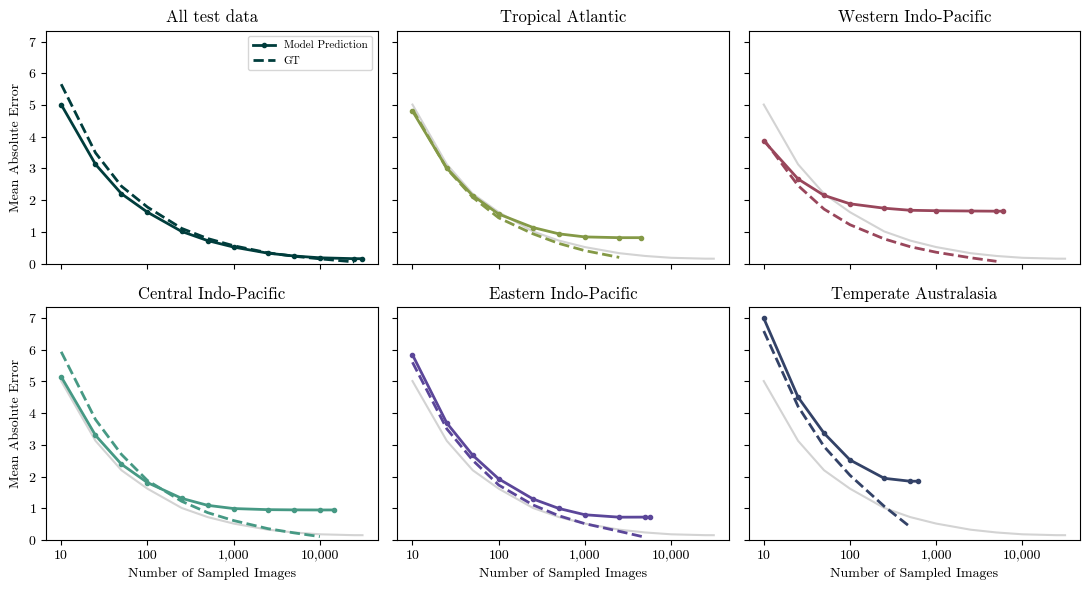

In [5]:
# Option 1: one panel per group; all test data in light gray behind every region for reference
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True, sharey=True)
for ax, g in zip(axes.flat, ["All test data", *REGIONS]):
    if g != "All test data":
        ns, gt, model = ERR["All test data"]
        ax.plot(ns, model, color="lightgray", lw=1.5)
    ns, gt, model = ERR[g]
    ax.plot(ns, model, marker="o", ms=3, color=COLORS[g], lw=2, label="Model Prediction")
    ax.plot(ns[:-1], gt[:-1], ls="--", color=COLORS[g], lw=2, label="GT")
    ax.set(xscale="log", title=g, ylim=(0, 1.05 * max(max(e[1].max(), e[2].max()) for e in ERR.values())))
    ax.set_xticks([10, 100, 1000, 10_000], ["10", "100", "1,000", "10,000"])
    ax.minorticks_off()
for ax in axes[1]:
    ax.set_xlabel("Number of Sampled Images")
for ax in axes[:, 0]:
    ax.set_ylabel("Mean Absolute Error")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

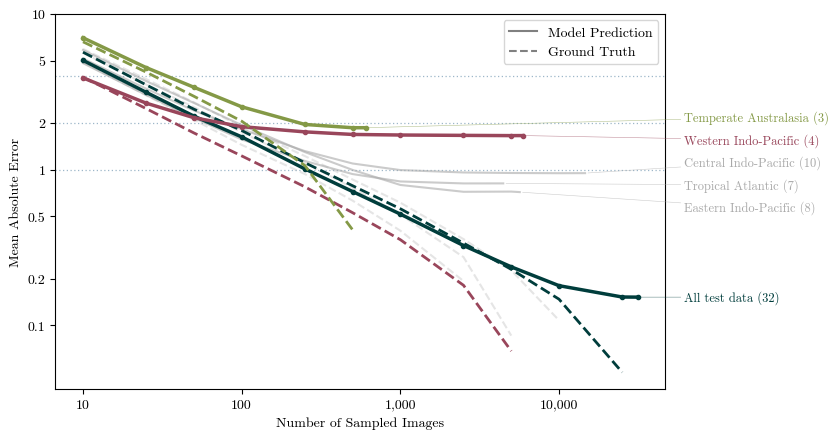

In [6]:
# Option 2: one panel, highlighted groups in colour, the rest in gray; every group labelled in the right margin
# Olive for Temperate Australasia: its palette blue (#334267) is too close to the all-test teal
HIGHLIGHT = {"All test data": "#003d3c", "Western Indo-Pacific": "#99465b", "Temperate Australasia": "#849946"}
OTHER = "darkgray"


def spread(y, gap, iters=200):
    """Move label positions y apart until neighbours are at least gap apart, each pair pushed symmetrically."""
    y = np.array(y, dtype=float)
    order = np.argsort(y)
    for _ in range(iters):
        ys = y[order]
        overlap = np.maximum(gap - np.diff(ys), 0) / 2
        if not overlap.any():
            break
        ys[:-1] -= overlap
        ys[1:] += overlap
        y[order] = ys
    return y


fig, ax = plt.subplots(figsize=(8.5, 4.5))
for g, (ns, gt, model) in ERR.items():
    if g not in HIGHLIGHT:
        ax.plot(ns, model, color=OTHER, lw=1.5, alpha=0.6)
        ax.plot(ns[:-1], gt[:-1], ls="--", color=OTHER, lw=1.5, alpha=0.3)
for g, color in HIGHLIGHT.items():
    ns, gt, model = ERR[g]
    ax.plot(ns, model, marker="o", ms=3, color=color, lw=2.5)
    ax.plot(ns[:-1], gt[:-1], ls="--", color=color, lw=2)
ax.set(xscale="log", yscale="log", xlabel="Number of Sampled Images", ylabel="Mean Absolute Error")
ax.set_yticks([0.1, 0.2, 0.5, 1, 2, 5, 10], ["0.1", "0.2", "0.5", "1", "2", "5", "10"])
ax.set_xticks([10, 100, 1000, 10_000], ["10", "100", "1,000", "10,000"])
ax.minorticks_off()
for lv in (1, 2, 4):
    ax.axhline(lv, color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)

# Labels in a column just right of the axes, joined to the line ends. Spaced in axes units (fraction of the height),
# so the spacing is the same on a linear or a log y-axis.
ends = {g: (e[0][-1], e[2][-1]) for g, e in ERR.items()}
data_to_axes = ax.transData + ax.transAxes.inverted()
label_y = spread([data_to_axes.transform(xy)[1] for xy in ends.values()], gap=0.06)
for (g, xy), y in zip(ends.items(), label_y):
    color = HIGHLIGHT.get(g, OTHER)
    ax.annotate(f"{g} ({len(groups[g])})", xy=xy, xytext=(1.03, y), textcoords="axes fraction", va="center", fontsize=9,
                color=color, fontweight="normal" if g in HIGHLIGHT else "normal", annotation_clip=False,
                arrowprops=dict(arrowstyle="-", color=color, lw=0.4, alpha=0.6, shrinkA=0, shrinkB=2))
ax.legend(handles=[plt.Line2D([], [], color="gray", label="Model Prediction"),
                   plt.Line2D([], [], color="gray", ls="--", label="Ground Truth")], fontsize=10)
# ax.axhline(1, color="gray", ls=":", lw=2)
fig.tight_layout()
plt.show()

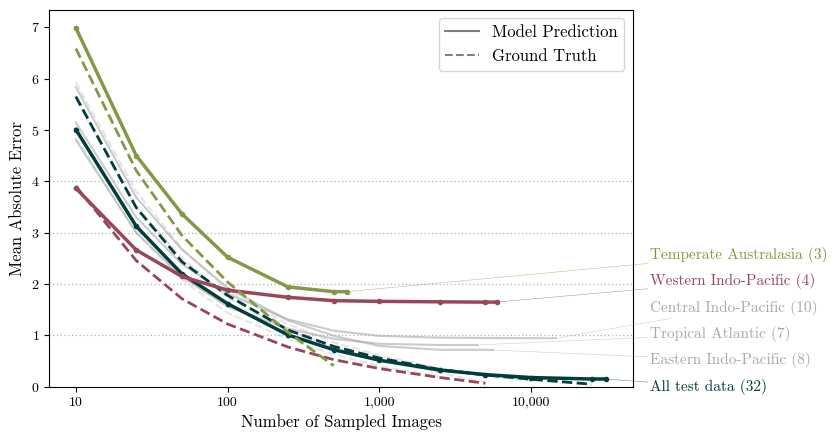

In [7]:
# Option 2: one panel, highlighted groups in colour, the rest in gray; every group labelled in the right margin
# Olive for Temperate Australasia: its palette blue (#334267) is too close to the all-test teal
HIGHLIGHT = {"All test data": "#003d3c", "Western Indo-Pacific": "#99465b", "Temperate Australasia": "#849946"}
OTHER = "darkgray"


def spread(y, gap, iters=200):
    """Move label positions y apart until neighbours are at least gap apart, each pair pushed symmetrically."""
    y = np.array(y, dtype=float)
    order = np.argsort(y)
    for _ in range(iters):
        ys = y[order]
        overlap = np.maximum(gap - np.diff(ys), 0) / 2
        if not overlap.any():
            break
        ys[:-1] -= overlap
        ys[1:] += overlap
        y[order] = ys
    return y


fig, ax = plt.subplots(figsize=(8.5, 4.5))
for g, (ns, gt, model) in ERR.items():
    if g not in HIGHLIGHT:
        ax.plot(ns, model, color=OTHER, lw=1.5, alpha=0.6)
        ax.plot(ns[:-1], gt[:-1], ls="--", color=OTHER, lw=1.5, alpha=0.3)
for g, color in HIGHLIGHT.items():
    ns, gt, model = ERR[g]
    ax.plot(ns, model, marker="o", ms=3, color=color, lw=2.5)
    ax.plot(ns[:-1], gt[:-1], ls="--", color=color, lw=2)
ax.set(xscale="log", xlabel="Number of Sampled Images", ylabel="Mean Absolute Error", ylim=(0, None))
ax.set_xlabel("Number of Sampled Images", fontsize=12)
ax.set_ylabel("Mean Absolute Error", fontsize=12)
ax.set_xticks([10, 100, 1000, 10_000], ["10", "100", "1,000", "10,000"])
ax.minorticks_off()
for lv in (1, 2, 3, 4):
    ax.axhline(lv, color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)

# Labels in a column just right of the axes (x in axes units, y in data units), joined to the line ends
ends = {g: (e[0][-1], e[2][-1]) for g, e in ERR.items()}
label_y = spread([y for _, y in ends.values()], gap=0.07 * ax.get_ylim()[1])
label_y -= min(label_y.min(), 0)  # keep the lowest label above the x-axis
for (g, xy), y in zip(ends.items(), label_y):
    color = HIGHLIGHT.get(g, OTHER)
    ax.annotate(f"{g} ({len(groups[g])})", xy=xy, xytext=(1.03, y), textcoords=ax.get_yaxis_transform(), va="center", fontsize=11,
                color=color, fontweight="normal" if g in HIGHLIGHT else "normal", annotation_clip=False,
                arrowprops=dict(arrowstyle="-", color=color, lw=0.4, alpha=0.6, shrinkA=0, shrinkB=2))
ax.legend(handles=[plt.Line2D([], [], color="gray", label="Model Prediction"),
                   plt.Line2D([], [], color="gray", ls="--", label="Ground Truth")], fontsize=12)
# ax.axhline(1, color="gray", ls=":", lw=2)
fig.tight_layout()
plt.show()

/data/vision/beery/scratch/viktordo/mermaid-segmentation/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)


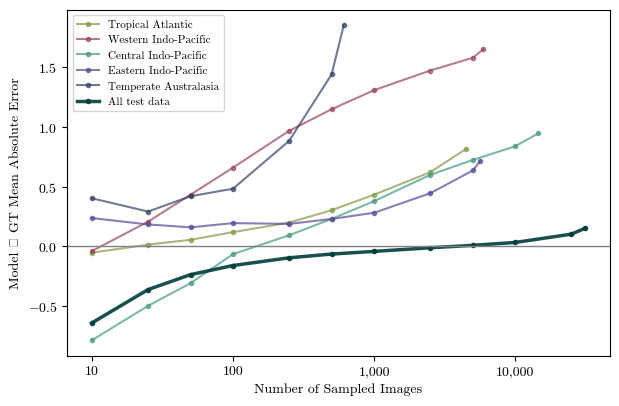

In [8]:
# Option 3: the extra error from using the model instead of annotations (model − GT mean absolute error)
fig, ax = plt.subplots(figsize=(7, 4.5))
for g, (ns, gt, model) in ERR.items():
    lw, alpha = (2.5, 0.9) if g == "All test data" else (1.5, 0.7)
    ax.plot(ns, model - gt, marker="o", ms=3, color=COLORS[g], lw=lw, alpha=alpha, label=g)
ax.axhline(0, color="gray", lw=1)
ax.set(xscale="log", xlabel="Number of Sampled Images", ylabel="Model − GT Mean Absolute Error")
ax.set_xticks([10, 100, 1000, 10_000], ["10", "100", "1,000", "10,000"])
ax.minorticks_off()
ax.legend(fontsize=8)
plt.show()

## Live coral cover: spread of source biases within a region

Bias = model cover from all pixels − annotated cover, in percentage points. Dots: single sources (size ∝ images).
Diamond: the pooled group (all its images), with a 95% bootstrap CI over images.

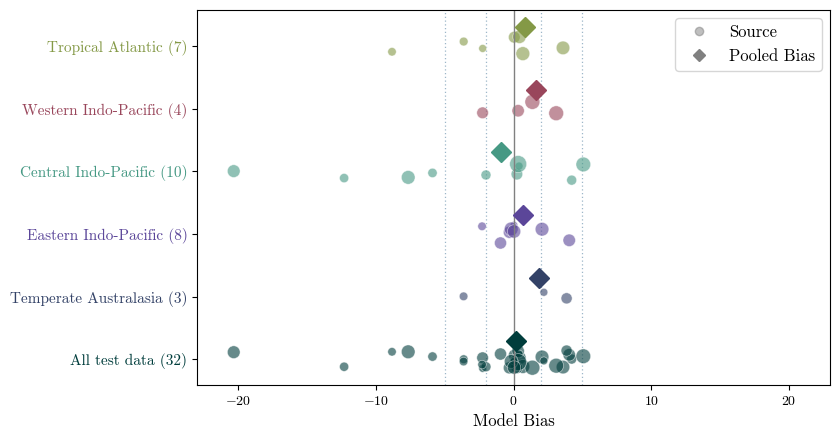

In [9]:
B = 2_000
rng = np.random.default_rng(0)
src = cover.groupby("source_id").agg(images=("image_id", "size"), truth=("truth", "mean"), model=("dense_live", "mean"))
src["bias"] = 100 * (src.model - src.truth)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for i, (g, sources) in enumerate(groups.items()):
    s = src.loc[sources]
    log_images = np.log(s.images)
    log_min, log_max = np.log(src.images.min()), np.log(src.images.max())
    sizes = 30 + 120 * (log_images - log_min) / (log_max - log_min)
    ax.scatter(s.bias, i + rng.uniform(-0.15, 0.15, len(s)), s=sizes,
               color=COLORS[g], alpha=0.6, marker="o", edgecolor="white", lw=0.5, zorder=2)
    # for sid, r in s[s.bias.abs() > 5].iterrows():  # name the extreme sources
    #     ax.annotate(sid, (r.bias, i), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8,
    #                 color=COLORS[g])
    d = cover[cover.source_id.isin(sources)]
    x = (d.dense_live - d.truth).to_numpy()
    boot = x[rng.integers(0, len(x), (B, len(x)))].mean(axis=1)
    lo, hi = 100 * np.quantile(boot, [0.025, 0.975])
    ax.errorbar(100 * x.mean(), i - 0.3, fmt="D", ms=10,
                color=COLORS[g], capsize=5, lw=1.5, zorder=3)
ax.axvline(0, color="gray", lw=1)
for lv in (-5, -2, 2, 5):
    ax.axvline(lv, color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
ax.set_yticks(range(len(groups)), [f"{g} ({len(s)})" for g, s in groups.items()], fontsize=11)
for t, g in zip(ax.get_yticklabels(), groups):
    t.set_color(COLORS[g])
ax.invert_yaxis()
ax.set_xlabel("Model Bias", fontsize=12)
ax.legend(handles=[plt.Line2D([], [], ls="", marker="o", color="gray", alpha=0.5, label="Source"),
                   plt.Line2D([], [], ls="", marker="D", color="gray", label="Pooled Bias")],
          fontsize=12, loc="upper right")
fig.tight_layout()
ax.set_xlim(-23, 23)
plt.show()

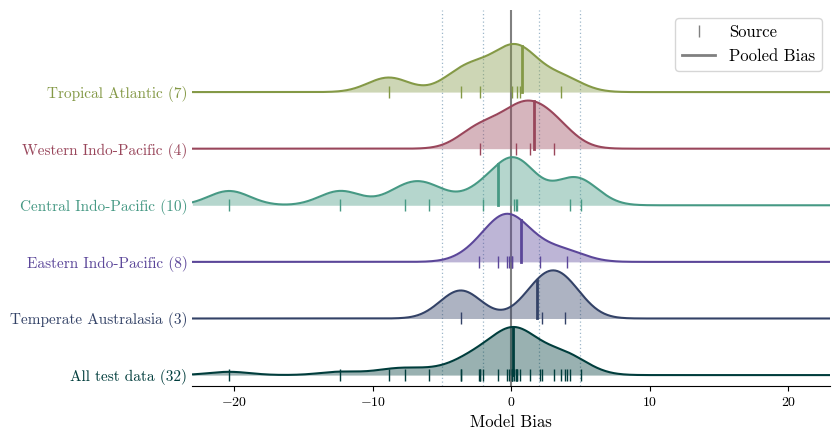

In [10]:
# Ridgeplot: one density of source biases per group (Gaussian kernel, every source weighted equally),
# sources as ticks underneath, the pooled bias (all images) as a vertical mark.
BW = 1.5  # kernel bandwidth (pp)
HEIGHT = 0.85  # ridge height relative to the row spacing (< 1: ridges do not overlap)
xs = np.linspace(-23, 23, 600)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for i, (g, sources) in enumerate(groups.items()):
    b = src.loc[sources, "bias"].to_numpy()
    dens = np.exp(-0.5 * ((xs[:, None] - b) / BW) ** 2).sum(axis=1)
    dens = HEIGHT * dens / dens.max()
    ax.fill_between(xs, -i, -i + dens, color=COLORS[g], alpha=0.4, lw=0, zorder=2 * i + 1)
    ax.plot(xs, -i + dens, color=COLORS[g], lw=1.5, zorder=2 * i + 2)
    ax.plot(b, np.full(len(b), -i), ls="", marker="|", ms=8, color=COLORS[g], zorder=2 * i + 2)
    d = cover[cover.source_id.isin(sources)]
    pooled = 100 * (d.dense_live - d.truth).mean()
    ax.plot([pooled, pooled], [-i, -i + np.interp(pooled, xs, dens)], color=COLORS[g], lw=2, zorder=2 * i + 2)
ax.axvline(0, color="gray", lw=1.5, zorder=0)
for lv in (-5, -2, 2, 5):
    ax.axvline(lv, color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
ax.set_yticks([-i for i in range(len(groups))], [f"{g} ({len(s)})" for g, s in groups.items()], fontsize=11)
for t, g in zip(ax.get_yticklabels(), groups):
    t.set_color(COLORS[g])
ax.set_xlabel("Model Bias", fontsize=12)
ax.set_xlim(-23, 23)
ax.set_ylim(-len(groups) + 0.8, HEIGHT + 0.6)  # headroom for the legend
ax.spines[["top", "left", "right"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(handles=[plt.Line2D([], [], ls="", marker="|", ms=8, color="gray", label="Source"),
                   plt.Line2D([], [], color="gray", lw=2, label="Pooled Bias")], fontsize=12, loc="upper right")
fig.tight_layout()
plt.show()

## Live coral cover: bias per source

One row per source, grouped by region and ordered by ground-truth cover within each region. Bias = model cover from
all pixels − annotated cover (pp), with a paired 95% bootstrap CI over images.

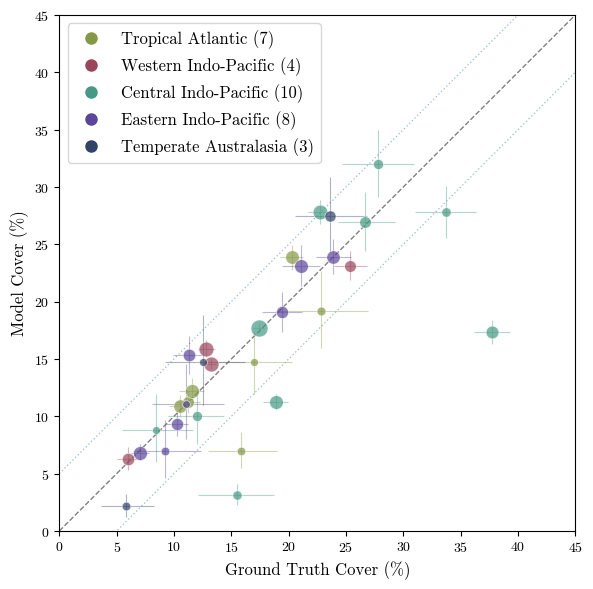

In [11]:
B = 2_000
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(6, 6))
log_min, log_max = np.log(src.images.min()), np.log(src.images.max())
for g, sources in REGIONS.items():
    for sid in sources:
        d = cover[cover.source_id == sid]
        boot = rng.integers(0, len(d), (B, len(d)))
        x, y = 100 * d.truth.to_numpy(), 100 * d.dense_live.to_numpy()
        (xlo, xhi), (ylo, yhi) = np.quantile(x[boot].mean(axis=1), [0.025, 0.975]), np.quantile(y[boot].mean(axis=1), [0.025, 0.975])
        size = 30 + 120 * (np.log(len(d)) - log_min) / (log_max - log_min)
        ax.errorbar(x.mean(), y.mean(), xerr=[[x.mean() - xlo], [xhi - x.mean()]], yerr=[[y.mean() - ylo], [yhi - y.mean()]],
                    color=COLORS[g], alpha=0.4, lw=0.8, capsize=0, zorder=2)
        ax.scatter(x.mean(), y.mean(), s=size, color=COLORS[g], alpha=0.7, edgecolor="white", lw=0.5, zorder=3)
lim = 45
ax.plot([0, lim], [0, lim], color="gray", lw=1, ls="--", zorder=1)
for off in (-5, 5):
    ax.plot([0, lim], [off, lim + off], color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
ax.set(xlim=(0, lim), ylim=(0, lim), aspect="equal")
ax.set_xlabel("Ground Truth Cover (%)", fontsize=12)
ax.set_ylabel("Model Cover (%)", fontsize=12)
ax.legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=8, color=COLORS[g], label=f"{g} ({len(s)})")
                   for g, s in REGIONS.items()], fontsize=12, loc="upper left")
fig.tight_layout()
plt.show()

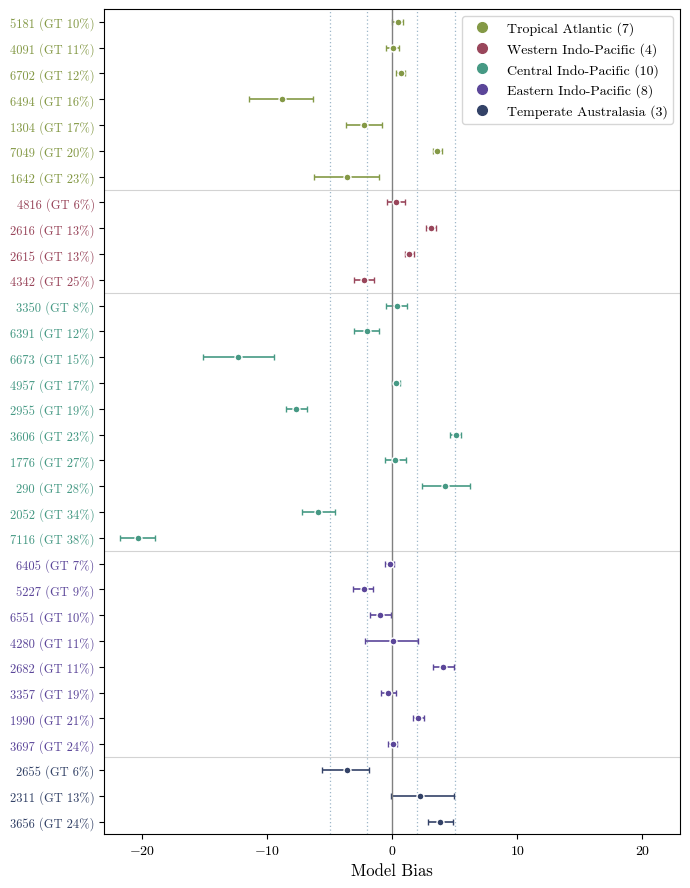

In [12]:
B = 2_000
rng = np.random.default_rng(0)

rows = []  # (region, source, GT cover, bias, CI low, CI high), in % / pp
for g, sources in REGIONS.items():
    for sid in sources:
        d = cover[cover.source_id == sid]
        x = 100 * (d.dense_live - d.truth).to_numpy()
        lo, hi = np.quantile(x[rng.integers(0, len(x), (B, len(x)))].mean(axis=1), [0.025, 0.975])
        rows.append((g, sid, 100 * d.truth.mean(), x.mean(), lo, hi))
per_src = pd.DataFrame(rows, columns=["region", "source", "gt", "bias", "lo", "hi"])
per_src = pd.concat([per_src[per_src.region == g].sort_values("gt") for g in REGIONS], ignore_index=True)

fig, ax = plt.subplots(figsize=(7, 9))
for i, r in per_src.iterrows():
    ax.errorbar(r.bias, i, xerr=[[r.bias - r.lo], [r.hi - r.bias]], fmt="o", ms=5, color=COLORS[r.region],
                mec="white", capsize=2, lw=1.2)
for i in np.flatnonzero(per_src.region.ne(per_src.region.shift()))[1:]:  # separate the regions
    ax.axhline(i - 0.5, color="lightgray", lw=0.8)
ax.axvline(0, color="gray", lw=1)
for lv in (-5, -2, 2, 5):
    ax.axvline(lv, color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
ax.set_yticks(range(len(per_src)), [f"{r.source} (GT {r.gt:.0f}%)" for r in per_src.itertuples()], fontsize=9)
for t, g in zip(ax.get_yticklabels(), per_src.region):
    t.set_color(COLORS[g])
ax.set_ylim(len(per_src) - 0.5, -0.5)
ax.set_xlabel("Model Bias", fontsize=12)
ax.legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=7, color=COLORS[g], label=f"{g} ({len(s)})")
                   for g, s in REGIONS.items()], fontsize=10, loc="upper right")
fig.tight_layout()
ax.set_xlim(-23, 23)
plt.show()

## Live coral genus diversity: model vs ground truth per source

From `Coral_Taxon_Diversity_Live_CD275k_Res768_Regions.ipynb` (section 2.1), model from all pixels only. Per source,
from all its images:
- **Richness**: number of genera present. Ground truth: at least one annotated live coral point of the genus; model: at
  least `TAU` = 1% of an image's pixels predicted live coral of the genus,
  with the confidence rule `P1_MIN` = 0.5 (a pixel keeps its genus only if the genus head's top probability is ≥ 0.5).
- **Effective number**: exp(Shannon entropy) of the summed abundances (point counts for the ground truth, pixel shares
  of the genera that pass `TAU` for the model).

Only sources reliably labelled to genus: ≥ 500 live coral points, ≥ 80% of them labelled to genus, and ≥ 3 genera with
50+ points.

In [13]:
TAU = 0.01  # minimum share of an image's pixels for a taxon to count as present (model, all pixels)
TAX = Path("../eval_out/taxon_diversity/test_cd275k_res768_step50000_viable")
tax_pts = pd.read_parquet(f"{TAX}.parquet")
P1_MIN = 0.5  # confidence rule: a live coral pixel keeps its genus / family only if the head's top probability >= P1_MIN
#              (None: no rule). Pixels that fail stay live coral without a taxon, so cover is unchanged.
if P1_MIN is None:
    tax_dense = pd.read_parquet(f"{TAX}_dense.parquet")
else:  # per-image pixel shares binned by top probability (0.05 bins, so multiples of 0.05 are exact), from the _conf run
    hist = pd.read_parquet(f"{TAX}_conf_hist.parquet")
    hist = hist[hist.p1_bin >= round(P1_MIN * 20)].astype({"level": str, "taxon": str})
    tax_dense = hist.groupby(["source_id", "image_id", "level", "taxon"]).share.sum().astype(float).reset_index()
concepts = pd.read_csv("model_checkpoints/cbm_scratch100k_kl_w0.5_taxv2/class_to_concepts.csv", dtype=str)
REGION_OF = {sid: g for g, sources in REGIONS.items() for sid in sources}
GENERA = set(concepts[concepts.order.str.lower() == "scleractinia"].genus.dropna().str.lower()) - {"not_given", "none"}


def hill1(counts):
    """Effective number of taxa: exp of the Shannon entropy of the abundances."""
    p = counts / counts.sum()
    return np.exp(-(p * np.log(p)).sum())


gt_live = tax_pts[tax_pts.gt_live & tax_pts.source_id.isin(REGION_OF)]
gt_genus = gt_live[gt_live.gt_genus.astype(str).isin(GENERA)]
model_genus = tax_dense[(tax_dense.level == "genus") & (tax_dense.share >= TAU)]

rows = []
for sid, d in gt_genus.groupby("source_id"):
    counts = d.gt_genus.astype(str).value_counts()
    eligible = (len(gt_live[gt_live.source_id == sid]) >= 500) and (len(d) / (gt_live.source_id == sid).sum() >= 0.8) \
        and (counts >= 50).sum() >= 3
    shares = model_genus[model_genus.source_id == sid].groupby(model_genus.taxon.astype(str)).share.sum()
    rows.append({"source": sid, "region": REGION_OF[sid], "eligible": eligible,
                 "images": (cover.source_id == sid).sum(),
                 "richness GT": len(counts), "richness model": len(shares),
                 "effective GT": hill1(counts), "effective model": hill1(shares)})
genus_src = pd.DataFrame(rows).set_index("source")
genus_src = genus_src[genus_src.eligible].drop(columns="eligible")
genus_src.round(1)

,region,images,richness GT,richness model,effective GT,effective model
source,,,,,,
290,Central Indo-Pacific,227,22,23,7.7,5.3
1990,Eastern Indo-Pacific,1233,4,7,1.9,1.7
2311,Temperate Australasia,111,3,10,2.6,3.0
2682,Eastern Indo-Pacific,675,5,7,2.4,2.0
3357,Eastern Indo-Pacific,564,6,7,2.3,2.1
3606,Central Indo-Pacific,2185,32,32,12.8,8.7
3656,Temperate Australasia,360,10,14,2.1,1.9
3697,Eastern Indo-Pacific,1048,16,7,3.0,3.1
4091,Tropical Atlantic,463,15,14,5.5,5.0


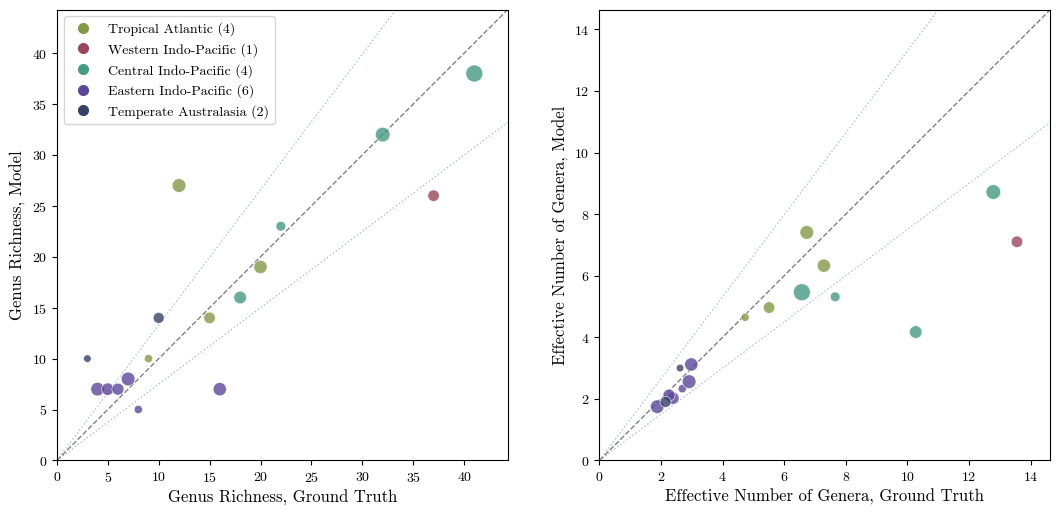

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
log_min, log_max = np.log(genus_src.images.min()), np.log(genus_src.images.max())
sizes = 30 + 120 * (np.log(genus_src.images) - log_min) / (log_max - log_min)
for ax, metric in zip(axes, ("richness", "effective")):
    x, y = genus_src[f"{metric} GT"], genus_src[f"{metric} model"]
    ax.scatter(x, y, s=sizes, c=genus_src.region.map(COLORS), alpha=0.8, edgecolor="white", lw=0.5, zorder=3)
    lim = 1.08 * max(x.max(), y.max())
    ax.plot([0, lim], [0, lim], color="gray", lw=1, ls="--", zorder=1)
    for f in (0.75, 1.33):  # half / double the annotated value
        ax.plot([0, lim], [0, f * lim], color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
    ax.set(xlim=(0, lim), ylim=(0, lim), aspect="equal")
    name = "Genus Richness" if metric == "richness" else "Effective Number of Genera"
    ax.set_xlabel(f"{name}, Ground Truth", fontsize=12)
    ax.set_ylabel(f"{name}, Model", fontsize=12)
n_src = genus_src.region.value_counts()
axes[0].legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=7, color=COLORS[g], label=f"{g} ({n_src.get(g, 0)})")
                        for g in REGIONS if g in n_src], fontsize=10, loc="upper left")
fig.tight_layout()
plt.show()

False and missed genera per source (model from all pixels, `TAU` = 1%, `P1_MIN` = 0.5): **false** = predicted in the source but
never annotated there; **missed** = annotated but never predicted. Label: source (annotated genera).

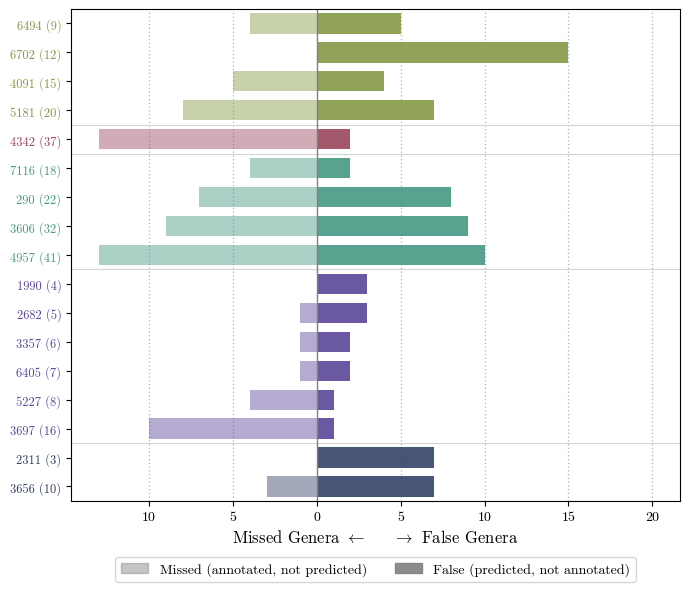

,region,annotated,correct,false,missed
source,,,,,
6494,Tropical Atlantic,9,5,5,4
6702,Tropical Atlantic,12,12,15,0
4091,Tropical Atlantic,15,10,4,5
5181,Tropical Atlantic,20,12,7,8
4342,Western Indo-Pacific,37,24,2,13
7116,Central Indo-Pacific,18,14,2,4
290,Central Indo-Pacific,22,15,8,7
3606,Central Indo-Pacific,32,23,9,9
4957,Central Indo-Pacific,41,28,10,13


In [15]:
rows = []
for sid in genus_src.index:
    gt = set(gt_genus[gt_genus.source_id == sid].gt_genus.astype(str))
    pred = set(model_genus[model_genus.source_id == sid].taxon.astype(str))
    rows.append({"source": sid, "region": REGION_OF[sid], "annotated": len(gt), "correct": len(gt & pred),
                 "false": len(pred - gt), "missed": len(gt - pred)})
genus_err = pd.DataFrame(rows)
genus_err = pd.concat([genus_err[genus_err.region == g].sort_values("annotated") for g in REGIONS], ignore_index=True)

fig, ax = plt.subplots(figsize=(7, 6))
colors = genus_err.region.map(COLORS)
y = np.arange(len(genus_err))
ax.barh(y, -genus_err.missed, color=colors, alpha=0.45, height=0.7)
ax.barh(y, genus_err["false"], color=colors, alpha=0.9, height=0.7)
for i in np.flatnonzero(genus_err.region.ne(genus_err.region.shift()))[1:]:  # separate the regions
    ax.axhline(i - 0.5, color="lightgray", lw=0.8)
ax.axvline(0, color="gray", lw=1)
for lv in (-10, -5, 5, 10, 15, 20):
    ax.axvline(lv, color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
ax.set_yticks(y, [f"{r.source} ({r.annotated})" for r in genus_err.itertuples()], fontsize=9)
for t, g in zip(ax.get_yticklabels(), genus_err.region):
    t.set_color(COLORS[g])
ax.set_ylim(len(genus_err) - 0.5, -0.5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{abs(v):g}"))
ax.set_xlabel(r"Missed Genera $\leftarrow$ $\quad$ $\rightarrow$ False Genera", fontsize=12)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="gray", alpha=0.45, label="Missed (annotated, not predicted)"),
                   plt.Rectangle((0, 0), 1, 1, color="gray", alpha=0.9, label="False (predicted, not annotated)")],
          fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
fig.tight_layout()
plt.show()
genus_err.set_index("source")

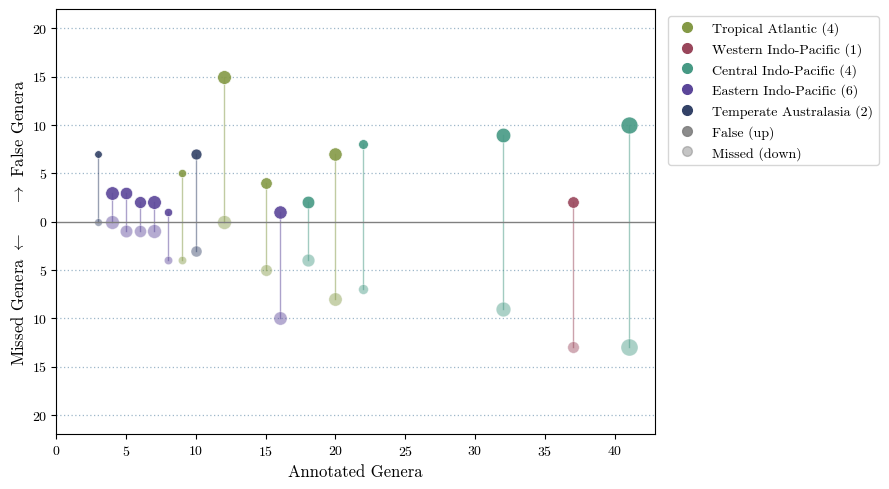

In [16]:
# The same counts against how many genera are annotated: false genera up, missed genera down, one line per source
fig, ax = plt.subplots(figsize=(9, 5))
log_min, log_max = np.log(genus_src.images.min()), np.log(genus_src.images.max())
for r in genus_err.itertuples():
    color, n_img = COLORS[r.region], genus_src.loc[r.source, "images"]
    size = 30 + 120 * (np.log(n_img) - log_min) / (log_max - log_min)
    ax.plot([r.annotated, r.annotated], [-r.missed, r.false], color=color, lw=1, alpha=0.5, zorder=1)
    ax.scatter(r.annotated, r.false, s=size, color=color, alpha=0.9, edgecolor="white", lw=0.5, zorder=3)
    ax.scatter(r.annotated, -r.missed, s=size, color=color, alpha=0.45, edgecolor="white", lw=0.5, zorder=2)
ax.axhline(0, color="gray", lw=1)
for lv in (-20, -15, -10, -5, 5, 10, 15, 20):
    ax.axhline(lv, color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{abs(v):g}"))
ax.set_xlim(0, None)
ax.set_xlabel("Annotated Genera", fontsize=12)
ax.set_ylabel(r"Missed Genera $\leftarrow$ $\quad$ $\rightarrow$ False Genera", fontsize=12)
n_src = genus_err.region.value_counts()
ax.legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=7, color=COLORS[g], label=f"{g} ({n_src[g]})")
                   for g in REGIONS if g in n_src]
          + [plt.Line2D([], [], ls="", marker="o", ms=7, color="gray", alpha=0.9, label="False (up)"),
             plt.Line2D([], [], ls="", marker="o", ms=7, color="gray", alpha=0.45, label="Missed (down)")],
          fontsize=10, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

## Live coral family diversity: model vs ground truth per source

As the genus figures above, at family level (needs the genus compute cell above for `gt_live`, `hill1` and `REGION_OF`).
Only sources reliably labelled to family: ≥ 500 live coral points, ≥ 80% of them labelled to family, and ≥ 3 families
with 50+ points.

In [17]:
FAMILIES = set(concepts[concepts.order.str.lower() == "scleractinia"].family.dropna().str.lower()) - {"not_given", "none"}
gt_family = gt_live[gt_live.gt_family.astype(str).isin(FAMILIES)]
model_family = tax_dense[(tax_dense.level == "family") & (tax_dense.share >= TAU)]

rows = []
for sid, d in gt_family.groupby("source_id"):
    counts = d.gt_family.astype(str).value_counts()
    eligible = (len(gt_live[gt_live.source_id == sid]) >= 500) and (len(d) / (gt_live.source_id == sid).sum() >= 0.8) \
        and (counts >= 50).sum() >= 3
    shares = model_family[model_family.source_id == sid].groupby(model_family.taxon.astype(str)).share.sum()
    rows.append({"source": sid, "region": REGION_OF[sid], "eligible": eligible,
                 "images": (cover.source_id == sid).sum(),
                 "richness GT": len(counts), "richness model": len(shares),
                 "effective GT": hill1(counts), "effective model": hill1(shares)})
family_src = pd.DataFrame(rows).set_index("source")
family_src = family_src[family_src.eligible].drop(columns="eligible")
family_src.round(1)

,region,images,richness GT,richness model,effective GT,effective model
source,,,,,,
1776,Central Indo-Pacific,447,5,13,1.9,2.0
1990,Eastern Indo-Pacific,1233,4,7,1.9,1.7
2311,Temperate Australasia,111,3,8,2.6,3.4
2682,Eastern Indo-Pacific,675,5,6,2.4,2.1
3357,Eastern Indo-Pacific,564,6,6,2.3,2.1
3606,Central Indo-Pacific,2185,13,14,6.1,5.3
3656,Temperate Australasia,360,5,8,2.0,2.0
3697,Eastern Indo-Pacific,1048,11,6,2.6,2.6
4091,Tropical Atlantic,463,10,10,5.1,5.0


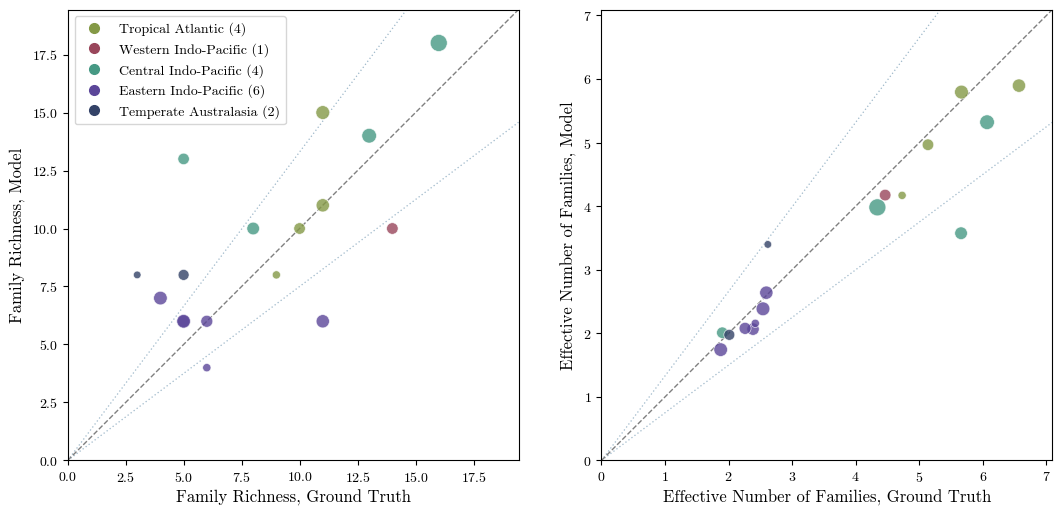

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
log_min, log_max = np.log(family_src.images.min()), np.log(family_src.images.max())
sizes = 30 + 120 * (np.log(family_src.images) - log_min) / (log_max - log_min)
for ax, metric in zip(axes, ("richness", "effective")):
    x, y = family_src[f"{metric} GT"], family_src[f"{metric} model"]
    ax.scatter(x, y, s=sizes, c=family_src.region.map(COLORS), alpha=0.8, edgecolor="white", lw=0.5, zorder=3)
    lim = 1.08 * max(x.max(), y.max())
    ax.plot([0, lim], [0, lim], color="gray", lw=1, ls="--", zorder=1)
    for f in (0.75, 1.33):  # half / double the annotated value
        ax.plot([0, lim], [0, f * lim], color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
    ax.set(xlim=(0, lim), ylim=(0, lim), aspect="equal")
    name = "Family Richness" if metric == "richness" else "Effective Number of Families"
    ax.set_xlabel(f"{name}, Ground Truth", fontsize=12)
    ax.set_ylabel(f"{name}, Model", fontsize=12)
n_src = family_src.region.value_counts()
axes[0].legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=7, color=COLORS[g], label=f"{g} ({n_src.get(g, 0)})")
                        for g in REGIONS if g in n_src], fontsize=10, loc="upper left")
fig.tight_layout()
plt.show()

False and missed families per source (model from all pixels, `TAU` = 1%, `P1_MIN` = 0.5). Label: source (annotated families).

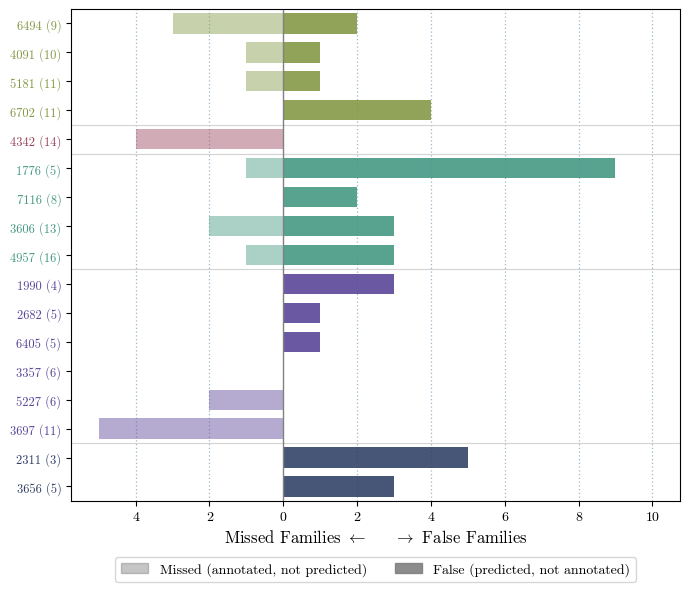

,region,annotated,correct,false,missed
source,,,,,
6494,Tropical Atlantic,9,6,2,3
4091,Tropical Atlantic,10,9,1,1
5181,Tropical Atlantic,11,10,1,1
6702,Tropical Atlantic,11,11,4,0
4342,Western Indo-Pacific,14,10,0,4
1776,Central Indo-Pacific,5,4,9,1
7116,Central Indo-Pacific,8,8,2,0
3606,Central Indo-Pacific,13,11,3,2
4957,Central Indo-Pacific,16,15,3,1


In [19]:
rows = []
for sid in family_src.index:
    gt = set(gt_family[gt_family.source_id == sid].gt_family.astype(str))
    pred = set(model_family[model_family.source_id == sid].taxon.astype(str))
    rows.append({"source": sid, "region": REGION_OF[sid], "annotated": len(gt), "correct": len(gt & pred),
                 "false": len(pred - gt), "missed": len(gt - pred)})
family_err = pd.DataFrame(rows)
family_err = pd.concat([family_err[family_err.region == g].sort_values("annotated") for g in REGIONS], ignore_index=True)

fig, ax = plt.subplots(figsize=(7, 6))
colors = family_err.region.map(COLORS)
y = np.arange(len(family_err))
ax.barh(y, -family_err.missed, color=colors, alpha=0.45, height=0.7)
ax.barh(y, family_err["false"], color=colors, alpha=0.9, height=0.7)
for i in np.flatnonzero(family_err.region.ne(family_err.region.shift()))[1:]:  # separate the regions
    ax.axhline(i - 0.5, color="lightgray", lw=0.8)
ax.axvline(0, color="gray", lw=1)
for lv in (-4, -2, 2, 4, 6, 8, 10):
    ax.axvline(lv, color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
ax.set_yticks(y, [f"{r.source} ({r.annotated})" for r in family_err.itertuples()], fontsize=9)
for t, g in zip(ax.get_yticklabels(), family_err.region):
    t.set_color(COLORS[g])
ax.set_ylim(len(family_err) - 0.5, -0.5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{abs(v):g}"))
ax.set_xlabel(r"Missed Families $\leftarrow$ $\quad$ $\rightarrow$ False Families", fontsize=12)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="gray", alpha=0.45, label="Missed (annotated, not predicted)"),
                   plt.Rectangle((0, 0), 1, 1, color="gray", alpha=0.9, label="False (predicted, not annotated)")],
          fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
fig.tight_layout()
plt.show()
family_err.set_index("source")

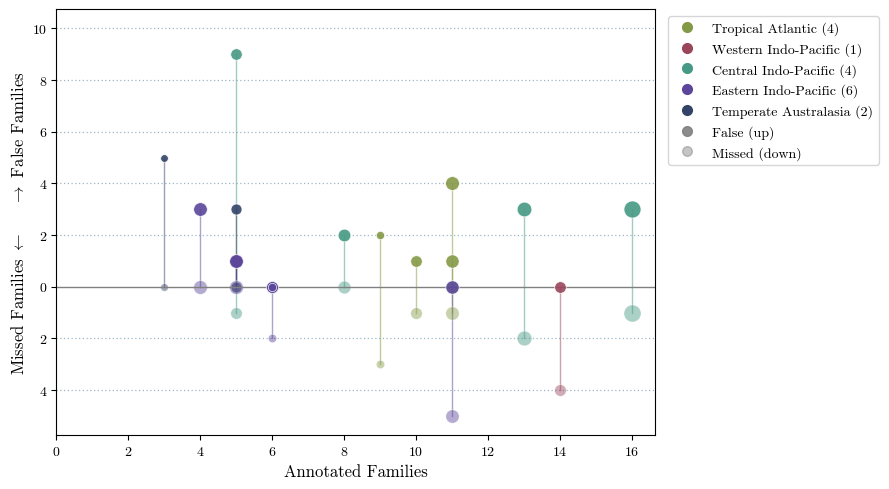

In [20]:
# The same counts against how many families are annotated: false families up, missed families down, one line per source
fig, ax = plt.subplots(figsize=(9, 5))
log_min, log_max = np.log(family_src.images.min()), np.log(family_src.images.max())
for r in family_err.itertuples():
    color, n_img = COLORS[r.region], family_src.loc[r.source, "images"]
    size = 30 + 120 * (np.log(n_img) - log_min) / (log_max - log_min)
    ax.plot([r.annotated, r.annotated], [-r.missed, r.false], color=color, lw=1, alpha=0.5, zorder=1)
    ax.scatter(r.annotated, r.false, s=size, color=color, alpha=0.9, edgecolor="white", lw=0.5, zorder=3)
    ax.scatter(r.annotated, -r.missed, s=size, color=color, alpha=0.45, edgecolor="white", lw=0.5, zorder=2)
ax.axhline(0, color="gray", lw=1)
for lv in (-4, -2, 2, 4, 6, 8, 10):
    ax.axhline(lv, color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{abs(v):g}"))
ax.set_xlim(0, None)
ax.set_xlabel("Annotated Families", fontsize=12)
ax.set_ylabel(r"Missed Families $\leftarrow$ $\quad$ $\rightarrow$ False Families", fontsize=12)
n_src = family_err.region.value_counts()
ax.legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=7, color=COLORS[g], label=f"{g} ({n_src[g]})")
                   for g in REGIONS if g in n_src]
          + [plt.Line2D([], [], ls="", marker="o", ms=7, color="gray", alpha=0.9, label="False (up)"),
             plt.Line2D([], [], ls="", marker="o", ms=7, color="gray", alpha=0.45, label="Missed (down)")],
          fontsize=10, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

## Live coral taxon composition: model vs ground truth, all test data pooled

One dot per taxon, pooled over the eligible sources of that level: share of the annotated live coral points (ground
truth) vs share of the model's predicted live coral pixels (all pixels, `TAU` = 1% per image, `P1_MIN` = 0.5). Log axes; dashed: 1:1,
dotted: within 2×. Dot area ∝ the number of images in which the taxon is annotated. Taxa the model never predicts sit
on the bottom edge (open). Labelled: the 10 most abundant taxa and those off by more than 3×.

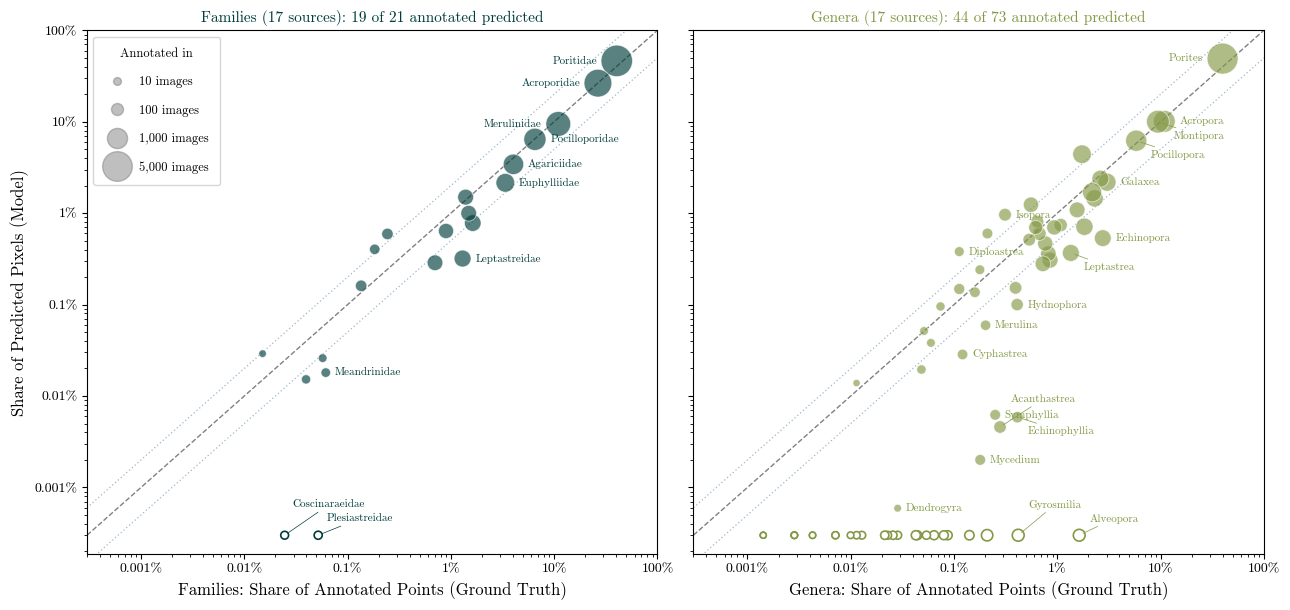

In [21]:
FLOOR = 3e-6  # where zero model abundance is drawn
N_TOP = 6  # label the most abundant taxa, plus those off by more than 3x


def place_labels(ax, items, color, fontsize=8):
    """Label (text, x, y, marker size, lift) points without overlaps: each label starts just past the right edge of its
    dot, ``lift`` points higher (> 0 for the markers on the bottom edge), and moves up / down in steps of one line
    until it is clear of the labels placed before it (thin line back to the point if moved)."""
    to_pt = lambda xy: ax.transData.transform(xy) * 72 / ax.figure.dpi  # data -> points
    placed = []
    for text, x, y, size, lift in sorted(items, key=lambda it: -it[2]):
        px, py = to_pt((x, y))
        dx = np.sqrt(size) / 2 + 3  # marker radius (points) + gap
        right_edge = ax.get_window_extent().x1 * 72 / ax.figure.dpi
        if px + dx + 0.5 * fontsize * len(text) + 2 > right_edge:  # no room on the right: label to the left
            dx = -dx
        w, h = 0.5 * fontsize * len(text) + 2, fontsize + 2
        for dy in [lift + d for d in [0] + [s * h * i for i in range(1, 8) for s in (1, -1)]]:
            x0 = px + dx if dx > 0 else px + dx - w
            box = (x0, py + dy - h / 2, x0 + w, py + dy + h / 2)
            if not any(box[0] < b[2] and b[0] < box[2] and box[1] < b[3] and b[1] < box[3] for b in placed):
                break
        placed.append(box)
        ax.annotate(text, (x, y), xytext=(dx, dy), textcoords="offset points", va="center", ha="left" if dx > 0 else "right", fontsize=fontsize,
                    color=color, arrowprops=dict(arrowstyle="-", color=color, lw=0.5, shrinkA=0, shrinkB=3) if dy else None)

PANELS = [("family", gt_family, model_family, family_src, "#003d3c", "Families"),
          ("genus", gt_genus, model_genus, genus_src, "#849946", "Genera")]

# One marker scale for both panels: area ∝ sqrt(images in which the taxon is annotated)
N_MAX = max(gt_pts[gt_pts.source_id.isin(src_tab.index)].groupby(gt_pts[f"gt_{lvl}"].astype(str)).image_id.nunique().max()
            for lvl, gt_pts, _, src_tab, _, _ in PANELS)
marker_size = lambda n: 12 + 500 * np.sqrt(n / N_MAX)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), sharex=True, sharey=True)
for ax, (lvl, gt_pts, model_pix, src_tab, color, name) in zip(axes, PANELS):
    gt_pts = gt_pts[gt_pts.source_id.isin(src_tab.index)]
    model_pix = model_pix[model_pix.source_id.isin(src_tab.index)]
    gt = gt_pts[f"gt_{lvl}"].astype(str).value_counts(normalize=True)
    model = model_pix.groupby(model_pix.taxon.astype(str)).share.sum().reindex(gt.index, fill_value=0)
    model = model / model_pix.share.sum()  # share of all predicted live coral pixels with a taxon
    n_img = gt_pts.groupby(gt_pts[f"gt_{lvl}"].astype(str)).image_id.nunique().reindex(gt.index)
    size = marker_size(n_img)
    zero = model == 0
    ax.plot([FLOOR, 1], [FLOOR, 1], color="gray", lw=1, ls="--", zorder=1)
    for f in (0.5, 2):
        ax.plot([FLOOR, 1], [f * FLOOR, f], color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
    ax.scatter(gt[~zero], model[~zero], s=size[~zero], color=color, alpha=0.65, edgecolor="white", lw=0.6, zorder=3)
    ax.scatter(gt[zero], np.full(zero.sum(), FLOOR), s=size[zero], facecolor="white", edgecolor=color, lw=1.2, zorder=3)
    ax.set(xscale="log", yscale="log", xlim=(FLOOR, 1), ylim=(FLOOR / 1.6, 1))
    ratio = model / gt
    show = set(gt.nlargest(N_TOP).index) | set(gt.index[~zero & (ratio > 3)]) \
        | set(gt.index[~zero & (ratio < 1 / 3) & (gt > 1e-4)]) | set(gt[zero].nlargest(2).index)  # + the 2 most abundant never predicted
    place_labels(ax, [(t.split("_")[0].capitalize(), gt[t], max(model[t], FLOOR), size[t], 12 if zero[t] else 0)
                       for t in show], color)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.3g}%"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.3g}%"))
    ax.set_xlabel(f"{name}: Share of Annotated Points (Ground Truth)", fontsize=12)
    ax.set_title(f"{name} ({len(src_tab)} sources): {int((~zero).sum())} of {len(gt)} annotated predicted",
                 fontsize=11, color=color)
axes[0].set_ylabel("Share of Predicted Pixels (Model)", fontsize=12)
axes[0].legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=np.sqrt(marker_size(n)), color="gray", alpha=0.5,
                                   label=f"{n:,} images")
                        for n in (10, 100, 1000, 5000)], title="Annotated in", fontsize=9, title_fontsize=9,
               loc="upper left", labelspacing=1.3, borderpad=0.9)
fig.tight_layout()
plt.show()

Families: 0 of 21 annotated test taxa have no training image
Genera: 2 of 73 annotated test taxa have no training image (gyrosmilia, sclerophyllia)


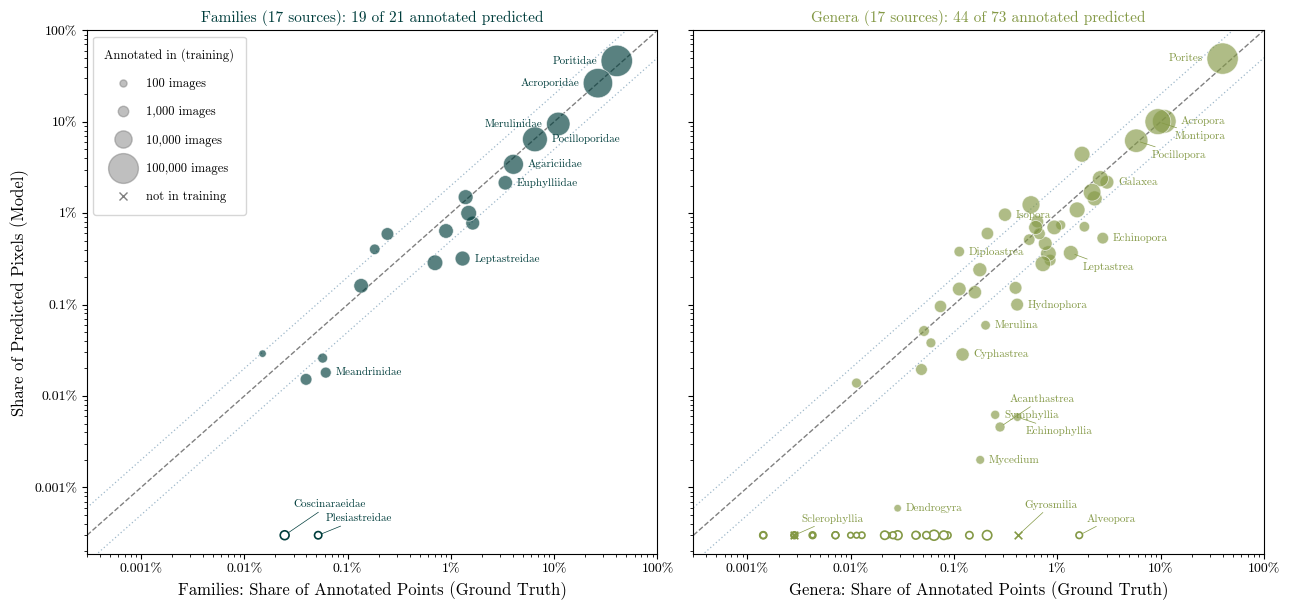

In [22]:
# Same figure, but marker area ∝ sqrt(number of TRAINING images in which the taxon is annotated as live scleractinian
# coral), over the model's training mixture (data_config_final_768.yaml: CoralNet train + val sources, MERMAID,
# CoralscapesV2, Catlin Seaview, Moorea, UCSD). Points or dense pixels, from scripts/train_label_counts.py, mapped to
# genus / family with the concept table. Crosses: annotated test taxa with no training image. Uses place_labels, PANELS.
train_lbl = pd.read_parquet("../dataset_stats/train_label_counts_final_768.parquet")
c2c = concepts.assign(dataset=concepts.source_dataset_source.str.strip().str.lower(),
                      label=concepts.source_label_class_name.str.strip().str.lower())
c2c = c2c[(c2c.order.str.lower() == "scleractinia") & (c2c.live.str.upper() == "TRUE")]
c2c = c2c.drop_duplicates(["dataset", "label"])[["dataset", "label", "genus", "family"]]
train_tax = train_lbl.merge(c2c, on=["dataset", "label"])
N_TRAIN = {lvl: train_tax.assign(t=train_tax[lvl].str.lower())[lambda d: d.t.isin(taxa)]
                    .drop_duplicates(["t", "dataset", "image_id"]).t.value_counts()
           for lvl, taxa in (("genus", GENERA), ("family", FAMILIES))}
N_TRAIN_MAX = max(n.max() for n in N_TRAIN.values())
train_size = lambda n: 12 + 500 * np.sqrt(n / N_TRAIN_MAX)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), sharex=True, sharey=True)
for ax, (lvl, gt_pts, model_pix, src_tab, color, name) in zip(axes, PANELS):
    gt_pts = gt_pts[gt_pts.source_id.isin(src_tab.index)]
    model_pix = model_pix[model_pix.source_id.isin(src_tab.index)]
    gt = gt_pts[f"gt_{lvl}"].astype(str).value_counts(normalize=True)
    model = model_pix.groupby(model_pix.taxon.astype(str)).share.sum().reindex(gt.index, fill_value=0)
    model = model / model_pix.share.sum()  # share of all predicted live coral pixels with a taxon
    n_train = N_TRAIN[lvl].reindex(gt.index, fill_value=0)
    size = train_size(n_train)
    zero, unseen = model == 0, n_train == 0
    ax.plot([FLOOR, 1], [FLOOR, 1], color="gray", lw=1, ls="--", zorder=1)
    for f in (0.5, 2):
        ax.plot([FLOOR, 1], [f * FLOOR, f], color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
    m = ~zero & ~unseen
    ax.scatter(gt[m], model[m], s=size[m], color=color, alpha=0.65, edgecolor="white", lw=0.6, zorder=3)
    m = zero & ~unseen
    ax.scatter(gt[m], np.full(m.sum(), FLOOR), s=size[m], facecolor="white", edgecolor=color, lw=1.2, zorder=3)
    ax.scatter(gt[unseen], np.maximum(model[unseen], FLOOR), marker="x", s=30, color=color, lw=1.2, zorder=4)
    ax.set(xscale="log", yscale="log", xlim=(FLOOR, 1), ylim=(FLOOR / 1.6, 1))
    ratio = model / gt
    show = set(gt.nlargest(N_TOP).index) | set(gt.index[~zero & (ratio > 3)]) \
        | set(gt.index[~zero & (ratio < 1 / 3) & (gt > 1e-4)]) | set(gt[zero].nlargest(2).index) | set(gt.index[unseen])
    place_labels(ax, [(t.split("_")[0].capitalize(), gt[t], max(model[t], FLOOR), size[t], 12 if zero[t] else 0)
                       for t in show], color)
    for t in ax.texts:
        t.set_zorder(5)  # labels above the markers
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.3g}%"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.3g}%"))
    ax.set_xlabel(f"{name}: Share of Annotated Points (Ground Truth)", fontsize=12)
    ax.set_title(f"{name} ({len(src_tab)} sources): {int((~zero).sum())} of {len(gt)} annotated predicted",
                 fontsize=11, color=color)
    print(f"{name}: {int(unseen.sum())} of {len(gt)} annotated test taxa have no training image"
          + (f" ({', '.join(gt.index[unseen])})" if unseen.any() else ""))
axes[0].set_ylabel("Share of Predicted Pixels (Model)", fontsize=12)
axes[0].legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=np.sqrt(train_size(n)), color="gray", alpha=0.5,
                                   label=f"{n:,} images")
                        for n in (100, 1_000, 10_000, 100_000)]
               + [plt.Line2D([], [], ls="", marker="x", ms=6, color="gray", label="not in training")],
               title="Annotated in (training)", fontsize=9, title_fontsize=9,
               loc="upper left", labelspacing=1.3, borderpad=0.9)
fig.tight_layout()
plt.show()

Families: 0 of 21 annotated test taxa have no training image
Genera: 2 of 73 annotated test taxa have no training image (gyrosmilia, sclerophyllia)


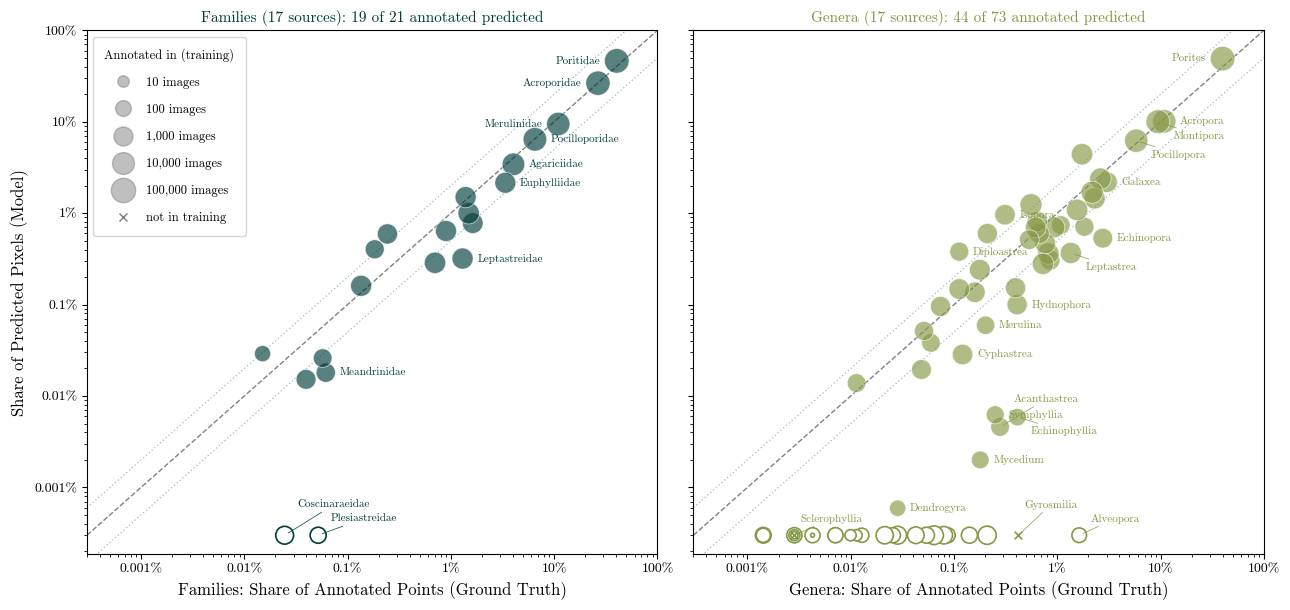

In [23]:
# Log-scaled version of the cell above: marker area ∝ log10(training images in which the taxon is annotated), so every
# 10x adds the same area and the visible size (radius) grows less with each decade: 10 -> 1,000 is a bigger step than
# 1,000 -> 100,000. Training data, counts and crosses as in the cell above.
train_lbl = pd.read_parquet("../dataset_stats/train_label_counts_final_768.parquet")
c2c = concepts.assign(dataset=concepts.source_dataset_source.str.strip().str.lower(),
                      label=concepts.source_label_class_name.str.strip().str.lower())
c2c = c2c[(c2c.order.str.lower() == "scleractinia") & (c2c.live.str.upper() == "TRUE")]
c2c = c2c.drop_duplicates(["dataset", "label"])[["dataset", "label", "genus", "family"]]
train_tax = train_lbl.merge(c2c, on=["dataset", "label"])
N_TRAIN = {lvl: train_tax.assign(t=train_tax[lvl].str.lower())[lambda d: d.t.isin(taxa)]
                    .drop_duplicates(["t", "dataset", "image_id"]).t.value_counts()
           for lvl, taxa in (("genus", GENERA), ("family", FAMILIES))}
N_TRAIN_MAX = max(n.max() for n in N_TRAIN.values())
train_size = lambda n: 8 + 60 * np.log10(np.maximum(n, 1))  # 1 image: 8, 10: 68, 1,000: 188, 100,000: 308 pt²

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), sharex=True, sharey=True)
for ax, (lvl, gt_pts, model_pix, src_tab, color, name) in zip(axes, PANELS):
    gt_pts = gt_pts[gt_pts.source_id.isin(src_tab.index)]
    model_pix = model_pix[model_pix.source_id.isin(src_tab.index)]
    gt = gt_pts[f"gt_{lvl}"].astype(str).value_counts(normalize=True)
    model = model_pix.groupby(model_pix.taxon.astype(str)).share.sum().reindex(gt.index, fill_value=0)
    model = model / model_pix.share.sum()  # share of all predicted live coral pixels with a taxon
    n_train = N_TRAIN[lvl].reindex(gt.index, fill_value=0)
    size = train_size(n_train)
    zero, unseen = model == 0, n_train == 0
    ax.plot([FLOOR, 1], [FLOOR, 1], color="gray", lw=1, ls="--", zorder=1)
    for f in (0.5, 2):
        ax.plot([FLOOR, 1], [f * FLOOR, f], color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
    m = ~zero & ~unseen
    ax.scatter(gt[m], model[m], s=size[m], color=color, alpha=0.65, edgecolor="white", lw=0.6, zorder=3)
    m = zero & ~unseen
    ax.scatter(gt[m], np.full(m.sum(), FLOOR), s=size[m], facecolor="white", edgecolor=color, lw=1.2, zorder=3)
    ax.scatter(gt[unseen], np.maximum(model[unseen], FLOOR), marker="x", s=30, color=color, lw=1.2, zorder=4)
    ax.set(xscale="log", yscale="log", xlim=(FLOOR, 1), ylim=(FLOOR / 1.6, 1))
    ratio = model / gt
    show = set(gt.nlargest(N_TOP).index) | set(gt.index[~zero & (ratio > 3)]) \
        | set(gt.index[~zero & (ratio < 1 / 3) & (gt > 1e-4)]) | set(gt[zero].nlargest(2).index) | set(gt.index[unseen])
    place_labels(ax, [(t.split("_")[0].capitalize(), gt[t], max(model[t], FLOOR), size[t], 12 if zero[t] else 0)
                       for t in show], color)
    for t in ax.texts:
        t.set_zorder(5)  # labels above the markers
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.3g}%"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.3g}%"))
    ax.set_xlabel(f"{name}: Share of Annotated Points (Ground Truth)", fontsize=12)
    ax.set_title(f"{name} ({len(src_tab)} sources): {int((~zero).sum())} of {len(gt)} annotated predicted",
                 fontsize=11, color=color)
    print(f"{name}: {int(unseen.sum())} of {len(gt)} annotated test taxa have no training image"
          + (f" ({', '.join(gt.index[unseen])})" if unseen.any() else ""))
axes[0].set_ylabel("Share of Predicted Pixels (Model)", fontsize=12)
axes[0].legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=np.sqrt(train_size(n)), color="gray", alpha=0.5,
                                   label=f"{n:,} images")
                        for n in (10, 100, 1_000, 10_000, 100_000)]
               + [plt.Line2D([], [], ls="", marker="x", ms=6, color="gray", label="not in training")],
               title="Annotated in (training)", fontsize=9, title_fontsize=9,
               loc="upper left", labelspacing=1.2, borderpad=0.9)
fig.tight_layout()
plt.show()

Families: 0 of 21 annotated test taxa have no training image
Genera: 2 of 73 annotated test taxa have no training image (gyrosmilia, sclerophyllia)


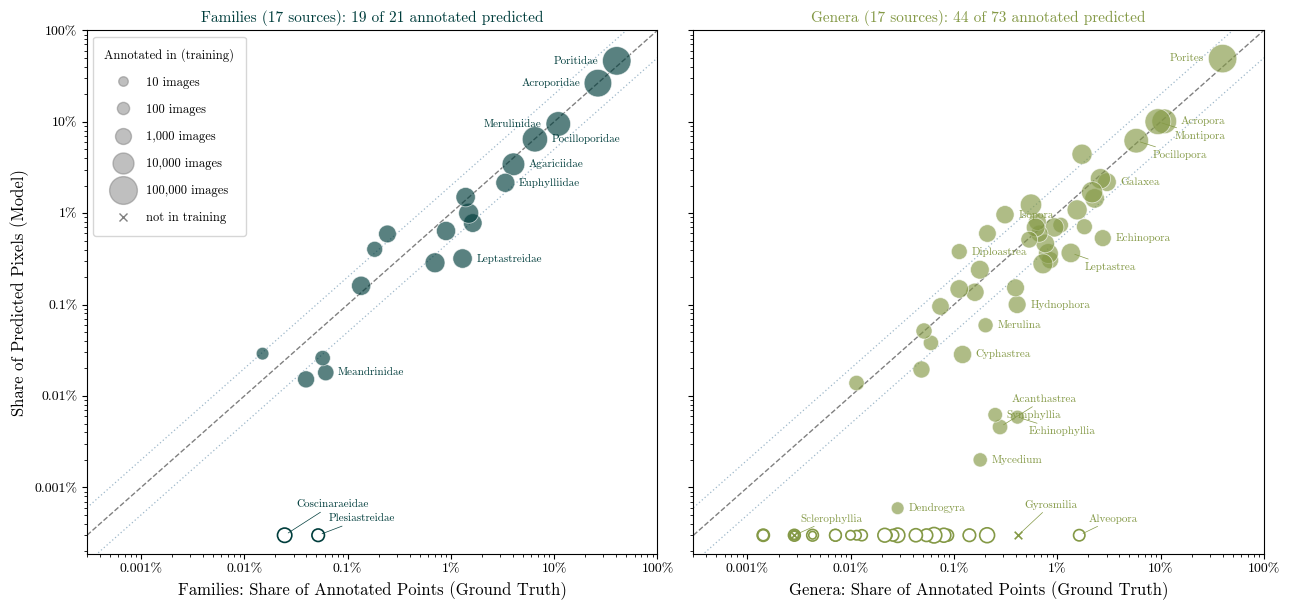

In [24]:
# Between the two cells above: marker area ∝ (training images in which the taxon is annotated)^0.25, flatter than the
# square root (cell 32) but not as flat as the log (cell 33). Training data, counts and crosses as in cell 32.
train_lbl = pd.read_parquet("../dataset_stats/train_label_counts_final_768.parquet")
c2c = concepts.assign(dataset=concepts.source_dataset_source.str.strip().str.lower(),
                      label=concepts.source_label_class_name.str.strip().str.lower())
c2c = c2c[(c2c.order.str.lower() == "scleractinia") & (c2c.live.str.upper() == "TRUE")]
c2c = c2c.drop_duplicates(["dataset", "label"])[["dataset", "label", "genus", "family"]]
train_tax = train_lbl.merge(c2c, on=["dataset", "label"])
N_TRAIN = {lvl: train_tax.assign(t=train_tax[lvl].str.lower())[lambda d: d.t.isin(taxa)]
                    .drop_duplicates(["t", "dataset", "image_id"]).t.value_counts()
           for lvl, taxa in (("genus", GENERA), ("family", FAMILIES))}
N_TRAIN_MAX = max(n.max() for n in N_TRAIN.values())
train_size = lambda n: 8 + 22 * np.power(n, 0.25)  # 1 image: 30, 10: 47, 1,000: 132, 100,000: 399 pt²

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), sharex=True, sharey=True)
for ax, (lvl, gt_pts, model_pix, src_tab, color, name) in zip(axes, PANELS):
    gt_pts = gt_pts[gt_pts.source_id.isin(src_tab.index)]
    model_pix = model_pix[model_pix.source_id.isin(src_tab.index)]
    gt = gt_pts[f"gt_{lvl}"].astype(str).value_counts(normalize=True)
    model = model_pix.groupby(model_pix.taxon.astype(str)).share.sum().reindex(gt.index, fill_value=0)
    model = model / model_pix.share.sum()  # share of all predicted live coral pixels with a taxon
    n_train = N_TRAIN[lvl].reindex(gt.index, fill_value=0)
    size = train_size(n_train)
    zero, unseen = model == 0, n_train == 0
    ax.plot([FLOOR, 1], [FLOOR, 1], color="gray", lw=1, ls="--", zorder=1)
    for f in (0.5, 2):
        ax.plot([FLOOR, 1], [f * FLOOR, f], color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
    m = ~zero & ~unseen
    ax.scatter(gt[m], model[m], s=size[m], color=color, alpha=0.65, edgecolor="white", lw=0.6, zorder=3)
    m = zero & ~unseen
    ax.scatter(gt[m], np.full(m.sum(), FLOOR), s=size[m], facecolor="white", edgecolor=color, lw=1.2, zorder=3)
    ax.scatter(gt[unseen], np.maximum(model[unseen], FLOOR), marker="x", s=30, color=color, lw=1.2, zorder=4)
    ax.set(xscale="log", yscale="log", xlim=(FLOOR, 1), ylim=(FLOOR / 1.6, 1))
    ratio = model / gt
    show = set(gt.nlargest(N_TOP).index) | set(gt.index[~zero & (ratio > 3)]) \
        | set(gt.index[~zero & (ratio < 1 / 3) & (gt > 1e-4)]) | set(gt[zero].nlargest(2).index) | set(gt.index[unseen])
    place_labels(ax, [(t.split("_")[0].capitalize(), gt[t], max(model[t], FLOOR), size[t], 12 if zero[t] else 0)
                       for t in show], color)
    for t in ax.texts:
        t.set_zorder(5)  # labels above the markers
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.3g}%"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.3g}%"))
    ax.set_xlabel(f"{name}: Share of Annotated Points (Ground Truth)", fontsize=12)
    ax.set_title(f"{name} ({len(src_tab)} sources): {int((~zero).sum())} of {len(gt)} annotated predicted",
                 fontsize=11, color=color)
    print(f"{name}: {int(unseen.sum())} of {len(gt)} annotated test taxa have no training image"
          + (f" ({', '.join(gt.index[unseen])})" if unseen.any() else ""))
axes[0].set_ylabel("Share of Predicted Pixels (Model)", fontsize=12)
axes[0].legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=np.sqrt(train_size(n)), color="gray", alpha=0.5,
                                   label=f"{n:,} images")
                        for n in (10, 100, 1_000, 10_000, 100_000)]
               + [plt.Line2D([], [], ls="", marker="x", ms=6, color="gray", label="not in training")],
               title="Annotated in (training)", fontsize=9, title_fontsize=9,
               loc="upper left", labelspacing=1.2, borderpad=0.9)
fig.tight_layout()
plt.show()

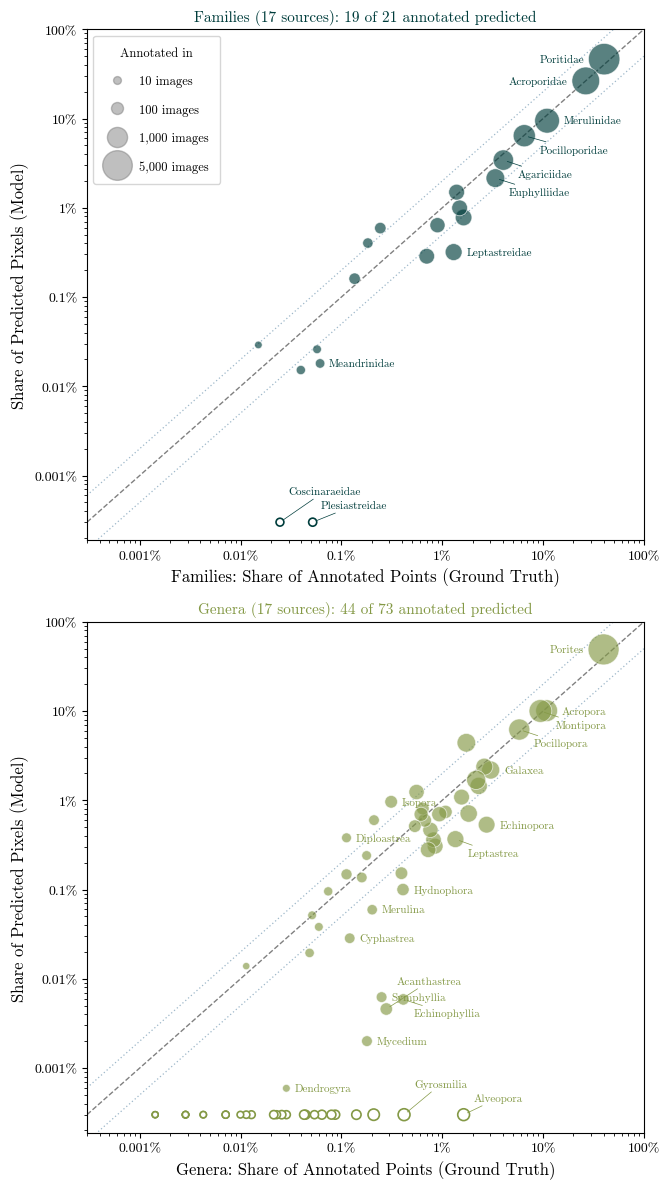

In [25]:
# Same figure in two rows (family on top, genus below); uses place_labels, PANELS and marker_size from above
fig, axes = plt.subplots(2, 1, figsize=(6.8, 12), sharex=True, sharey=True)
for ax, (lvl, gt_pts, model_pix, src_tab, color, name) in zip(axes, PANELS):
    gt_pts = gt_pts[gt_pts.source_id.isin(src_tab.index)]
    model_pix = model_pix[model_pix.source_id.isin(src_tab.index)]
    gt = gt_pts[f"gt_{lvl}"].astype(str).value_counts(normalize=True)
    model = model_pix.groupby(model_pix.taxon.astype(str)).share.sum().reindex(gt.index, fill_value=0)
    model = model / model_pix.share.sum()  # share of all predicted live coral pixels with a taxon
    n_img = gt_pts.groupby(gt_pts[f"gt_{lvl}"].astype(str)).image_id.nunique().reindex(gt.index)
    size = marker_size(n_img)
    zero = model == 0
    ax.plot([FLOOR, 1], [FLOOR, 1], color="gray", lw=1, ls="--", zorder=1)
    for f in (0.5, 2):
        ax.plot([FLOOR, 1], [f * FLOOR, f], color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
    ax.scatter(gt[~zero], model[~zero], s=size[~zero], color=color, alpha=0.65, edgecolor="white", lw=0.6, zorder=3)
    ax.scatter(gt[zero], np.full(zero.sum(), FLOOR), s=size[zero], facecolor="white", edgecolor=color, lw=1.2, zorder=3)
    ax.set(xscale="log", yscale="log", xlim=(FLOOR, 1), ylim=(FLOOR / 1.6, 1))
    ratio = model / gt
    show = set(gt.nlargest(N_TOP).index) | set(gt.index[~zero & (ratio > 3)]) \
        | set(gt.index[~zero & (ratio < 1 / 3) & (gt > 1e-4)]) | set(gt[zero].nlargest(2).index)  # + the 2 most abundant never predicted
    place_labels(ax, [(t.split("_")[0].capitalize(), gt[t], max(model[t], FLOOR), size[t], 12 if zero[t] else 0)
                       for t in show], color)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.3g}%"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.3g}%"))
    ax.set_xlabel(f"{name}: Share of Annotated Points (Ground Truth)", fontsize=12)
    ax.set_title(f"{name} ({len(src_tab)} sources): {int((~zero).sum())} of {len(gt)} annotated predicted",
                 fontsize=11, color=color)
for ax in axes:
    ax.set_ylabel("Share of Predicted Pixels (Model)", fontsize=12)
    ax.xaxis.set_tick_params(labelbottom=True)  # tick labels on both rows
axes[0].legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=np.sqrt(marker_size(n)), color="gray", alpha=0.5,
                                   label=f"{n:,} images")
                        for n in (10, 100, 1000, 5000)], title="Annotated in", fontsize=9, title_fontsize=9,
               loc="upper left", labelspacing=1.3, borderpad=0.9)
fig.tight_layout()
plt.show()

## TEMPORARY: source 6673 (OTI) annotations vs predictions

768 px model, live hard coral. Panels: the bare image, P(order = scleractinia), and P(scleractinia) × P(live).
Points: yellow = annotated live hard coral, blue = not, gray = not given. A magenta ring means the model calls the point
coral. Needs the GPU; loading the model takes about 45 s.

In [26]:
import os
import sys

os.environ.setdefault("HF_HOME", "/data/vision/beery/scratch/viktordo/hf-cache")  # gated DINOv3 backbone config
sys.path.insert(0, "../scripts")
import qualitative_overlays as qo

OTI = qo.load_context(run="cbm_scratch100k_kl_w0.5_taxv2", sources=[6673], resolution=768, target="live_hard",
                      step_dir="/data/vision/beery/scratch/sauder/mermaid-segmentation-final/nbs/model_checkpoints/cbm_cd275000_res768/model_step50000")
oti_imgs = qo.sample_images(OTI, n_per_source=6, seed=0)

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

In [27]:
# for _, meta in oti_imgs.iterrows():
#     qo.render(qo.predict_image(OTI, meta), panels=("hard", "live_hard"), show_raw=True)
#     plt.show()

## TEMPORARY: source 7116 (Guam) annotations vs predictions

At the points the model is close (+1.5 pp), but from all pixels it is −20 pp: it calls about 48% of the pixels
scleractinia but only 17% live. The extra middle panel shows P(live) to see where the live head rejects coral.
Runs on its own (loads the model again, about 45 s).

In [28]:
import os
import sys

os.environ.setdefault("HF_HOME", "/data/vision/beery/scratch/viktordo/hf-cache")  # gated DINOv3 backbone config
sys.path.insert(0, "../scripts")
import qualitative_overlays as qo

GUAM = qo.load_context(run="cbm_scratch100k_kl_w0.5_taxv2", sources=[7116], resolution=768, target="live_hard",
                       step_dir="/data/vision/beery/scratch/sauder/mermaid-segmentation-final/nbs/model_checkpoints/cbm_cd275000_res768/model_step50000")
guam_imgs = qo.sample_images(GUAM, n_per_source=6, seed=0)

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

In [29]:
# for _, meta in guam_imgs.iterrows():
#     qo.render(qo.predict_image(GUAM, meta), panels=("hard", "live", "live_hard"), show_raw=True)
#     plt.show()